# Training a circuit on MNIST with data-driven initialization

This notebook shows an end-to-end example of **unsupervised density estimation** on MNIST. We construct a categorical probabilistic circuit, initialize its parameters from training images with `DataDrivenInitialization`, optimize it by maximum likelihood, and evaluate its negative log-likelihood (NLL) and bits per dimension (bpd).

The circuit learns a distribution over images, $p_\theta(\mathbf{x})$. For the theory behind population propagation, smoothing, and symmetry breaking, see the [data-driven initialization handbook](../docs/handbooks/data-driven-initialization.md).

## 1. Configuration

The experiment uses 50,000 MNIST images for training, 10,000 for validation, and the separate 10,000-image test split. Training is controlled by optimizer steps: `MAX_TRAIN_STEPS` is the update budget and `VALIDATION_STEPS` is the interval between validation passes.

In [2]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch.optim import Adam
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import MNIST
from tqdm.auto import tqdm

from cirkit.backend.torch.layers import TorchInputLayer
from cirkit.pipeline import PipelineContext
import cirkit.symbolic.functional as sf
from cirkit.templates.data_modalities import image_data
from cirkit.templates.initialization import DataDrivenInitialization
from cirkit.templates.utils import POSITIVE_PARAMETER_MIN, Parameterization

SEED = 42
IMAGE_SHAPE = (1, 28, 28)
NUM_PIXELS = 28 * 28

TRAIN_SAMPLES = 50_000
VALID_SAMPLES = 10_000
TEST_SAMPLES = 10_000
NUM_UNITS = 8
MAX_TRAIN_STEPS = 1_000
VALIDATION_STEPS = 250
SUM_WEIGHT_ACTIVATION = "none"
BATCH_SIZE = 256
LEARNING_RATE = 1e-2

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

## 2. Load discrete MNIST images

Categorical image inputs expect integer observations in $\{0,\ldots,255\}$. The `data` tensor stored by `torchvision.datasets.MNIST` already has dtype `uint8`, so no floating-point normalization is needed. We flatten each image to the `(batch, 784)` representation expected by the compiled circuit.

In [3]:
data_root = Path.home() / ".cache" / "cirkit" / "datasets"
mnist_train = MNIST(root=data_root, train=True, download=True)
mnist_test = MNIST(root=data_root, train=False, download=True)

generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(mnist_train), generator=generator)
train_indices = indices[:TRAIN_SAMPLES]
valid_indices = indices[TRAIN_SAMPLES : TRAIN_SAMPLES + VALID_SAMPLES]

train_images = mnist_train.data[train_indices].reshape(-1, NUM_PIXELS).contiguous()
valid_images = mnist_train.data[valid_indices].reshape(-1, NUM_PIXELS).contiguous()
test_images = mnist_test.data[:TEST_SAMPLES].reshape(-1, NUM_PIXELS).contiguous()

train_loader = DataLoader(TensorDataset(train_images), batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(TensorDataset(valid_images), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(test_images), batch_size=BATCH_SIZE, shuffle=False)

train_images.shape, train_images.dtype, (train_images.min().item(), train_images.max().item())

(torch.Size([50000, 784]), torch.uint8, (0, 255))

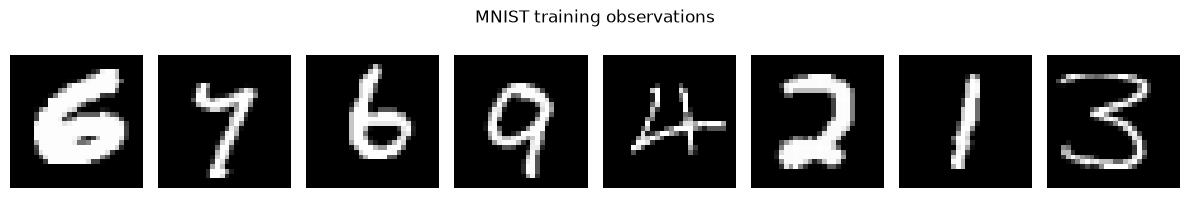

In [4]:
figure, axes = plt.subplots(1, 8, figsize=(12, 2))
for axis, image in zip(axes, train_images[:8]):
    axis.imshow(image.reshape(28, 28), cmap="gray", vmin=0, vmax=255)
    axis.axis("off")
figure.suptitle("MNIST training observations")
plt.tight_layout()

## 3. Construct and initialize the symbolic circuit

`image_data` first constructs a fixed smooth and decomposable circuit from a QuadGraph region graph. Because both `data` and `initialization` are supplied, Cirkit then propagates populations through that structure and initializes:

- categorical input probabilities from smoothed pixel counts;
- sum weights from the sizes of data clusters;
- replicated tensor units with seeded symmetry-breaking noise.

All training images are used for initialization and subsequent optimization. Here `alpha=5.0` is a pseudocount added to every pixel category and every mixture branch, and `noise_scale=2.0` breaks symmetry between replicated units. Categorical inputs use softmax; `SUM_WEIGHT_ACTIVATION` configures only the sum weights.

In [5]:
initialization_data = train_images.to(device)
sum_weight_param = Parameterization(activation=SUM_WEIGHT_ACTIVATION)

symbolic_circuit = image_data(
    IMAGE_SHAPE,
    region_graph="quad-graph",
    input_layer="categorical",
    num_input_units=NUM_UNITS,
    sum_product_layer="cp",
    num_sum_units=NUM_UNITS,
    use_mixing_weights=True,
    input_sharing="none",
    data=initialization_data,
    sum_weight_param=sum_weight_param,
    initialization=DataDrivenInitialization(
        alpha=5.0,
        noise_scale=2.0,
        seed=SEED,
    ),
)

assert symbolic_circuit.is_smooth
assert symbolic_circuit.is_decomposable
len(list(symbolic_circuit.layers))

5725

## 4. Compile the circuit

The `lse-sum` semiring evaluates the circuit in log space. Compile the circuit and its symbolic integral with the same context so that they share parameters, `partition()` then returns the current log Z. With raw sum weights, log Z need not be zero, and the normalized log-likelihood is `circuit(batch) - partition()`.

For `SUM_WEIGHT_ACTIVATION="none"`, collect the raw sum parameters once and clamp them before the first forward pass and after each optimizer step. Input logits remain unconstrained. With softmax or another local sum-weight activation.

In [8]:
context = PipelineContext(backend="torch", semiring="lse-sum", fold=True, optimize=True)
circuit = context.compile(symbolic_circuit).to(device)
partition = context.compile(sf.integrate(symbolic_circuit)).to(device)

projected_sum_parameters = (
    list(
        {
            id(p): p
            for layer in circuit.layers
            if not isinstance(layer, TorchInputLayer)
            for p in layer.parameters()
        }.values()
    )
    if sum_weight_param.activation == "none"
    else []
)

@torch.no_grad()
def project_sum_weights():
    for p in projected_sum_parameters:
        p.clamp_(min=POSITIVE_PARAMETER_MIN)


project_sum_weights()
with torch.no_grad():
    log_partition = partition().item()

num_parameters = sum(parameter.numel() for parameter in circuit.parameters())
print(f"Device: {device}")
print(f"Trainable parameters: {num_parameters:,}")
print(f"log Z: {log_partition:.6f}")

Device: cpu
Trainable parameters: 1,809,458
log Z: 3011.868896


## 6. Maximum-likelihood training by steps

`DataDrivenInitialization` chooses the starting parameters. Adam then minimizes the normalized NLL for a fixed number of minibatch updates. After raw sum weights are updated, `project_sum_weights()` keeps them positive.

Validation runs every `VALIDATION_STEPS` updates and at the final step. The loop may make several passes through `train_loader` until it reaches `MAX_TRAIN_STEPS`.

In [10]:
@torch.inference_mode()
def evaluate(data_loader):
    circuit.eval()
    total_nll = torch.zeros((), dtype=torch.float64, device=device)
    total_samples = 0

    for (batch,) in data_loader:
        batch = batch.to(device=device, dtype=torch.long)
        total_nll.add_(nll(batch).to(torch.float64), alpha=batch.size(0))
        total_samples += batch.size(0)

    mean_nll = total_nll.item() / total_samples
    bits_per_dimension = mean_nll / (NUM_PIXELS * math.log(2.0))

    return mean_nll, bits_per_dimension

def nll(batch):
    # Ricalcola log Z mantenendo i gradienti durante il training.
    return -(circuit(batch) - partition()).mean()

In [11]:
project_sum_weights()
optimizer = Adam(circuit.parameters(), lr=LEARNING_RATE)
history = []
total_steps = 0
train_nll_sum = 0.0
train_samples = 0

with tqdm(total=MAX_TRAIN_STEPS, desc="Train", unit="step") as progress:
    while total_steps < MAX_TRAIN_STEPS:
        circuit.train()
        for (batch,) in train_loader:
            batch = batch.to(device=device, dtype=torch.long)
            optimizer.zero_grad(set_to_none=True)

            loss = nll(batch)
            loss.backward()
            optimizer.step()
            project_sum_weights()

            train_nll_sum += loss.item() * batch.size(0)
            train_samples += batch.size(0)
            total_steps += 1
            progress.update(1)

            if total_steps % VALIDATION_STEPS == 0 or total_steps == MAX_TRAIN_STEPS:
                train_nll = train_nll_sum / train_samples
                train_bpd = train_nll / (NUM_PIXELS * math.log(2.0))
                val_nll, val_bpd = evaluate(valid_loader)
                history.append(
                    {
                        "step": total_steps,
                        "train_nll": train_nll,
                        "train_bpd": train_bpd,
                        "val_nll": val_nll,
                        "val_bpd": val_bpd,
                    }
                )
                progress.write(
                    f"Step {total_steps:05d} | "
                    f"train NLL {train_nll:.3f}, bpd {train_bpd:.3f} | "
                    f"validation NLL {val_nll:.3f}, bpd {val_bpd:.3f}"
                )
                train_nll_sum = 0.0
                train_samples = 0
                circuit.train()

            if total_steps >= MAX_TRAIN_STEPS:
                break

Train:  25%|██▌       | 250/1000 [01:37<04:23,  2.84step/s]

Step 00250 | train NLL 915.857, bpd 1.685 | validation NLL 817.030, bpd 1.503


Train:  50%|█████     | 500/1000 [03:15<02:56,  2.84step/s]

Step 00500 | train NLL 792.302, bpd 1.458 | validation NLL 776.112, bpd 1.428


Train:  75%|███████▌  | 750/1000 [05:09<03:22,  1.23step/s]

Step 00750 | train NLL 764.935, bpd 1.408 | validation NLL 757.064, bpd 1.393


Train: 100%|██████████| 1000/1000 [08:49<00:00,  1.89step/s]

Step 01000 | train NLL 749.553, bpd 1.379 | validation NLL 746.333, bpd 1.373


## 7. Test-set evaluation

Evaluate the final trained circuit on the held-out MNIST test split. The test data is used only here, after training is complete.

In [12]:
final_val_nll, final_val_bpd = evaluate(valid_loader)
test_nll, test_bpd = evaluate(test_loader)
print(f"Test NLL: {test_nll:.3f}")
print(f"Test bits per dimension: {test_bpd:.3f}")

Test NLL: 743.484
Test bits per dimension: 1.368
